# Recognition under data scarcity

Prof. Awais asked what algorithms might work given how little data we have. This notebook
tests that question directly, and the answer **reverses a conclusion from
`letter_classifier.ipynb`**.

The situation: 40 letter classes, ~1,345 independent letter occurrences, five signers, and
pseudo-labels rather than ground truth. Eight letters appear five times in the entire corpus.

`letter_classifier.ipynb` concluded that landmark geometry cannot do this job (6.8 % against a
9.1 % majority baseline, worse than guessing) and that we should move to image features. That
conclusion rested on three handicaps stacked together, and removing them changes the answer.

## The three handicaps

1. **Raw coordinates.** Wrist-centred, scaled, de-rotated landmark positions still encode hand
   *morphology*. Finger lengths differ between people, so the coordinates do too — which is
   exactly the "features describe the signer" problem we measured at 97 %.

2. **A distorted coordinate space.** The landmarks in `hand_keypoints_features.csv` are
   normalised by the original 16:9 frame, so x and y sit on different pixel scales. Any angle
   computed from them is skewed. We re-detect on the cropped videos to get isotropic pixel
   coordinates.

3. **A linear classifier.** Logistic regression over 40 classes with ~1,300 samples is the
   wrong tool. This is the point Prof. Awais was making: with scarce data the *estimator*
   matters as much as the representation.

The fix for (1) is to use quantities that are invariant to hand size and finger length. A joint
angle is: two people with very different hands bend a joint through the same angle to form the
same letter. `hand_geometry.py` builds 19 joint angles and 55 palm-normalised pairwise
distances — 74 features, against 1,764 for HOG.

## Setup

In [1]:
import json, os, collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from hand_geometry import joint_angles, normalised_distances, hand_features

pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

# Landmarks re-detected at each hold frame, in ISOTROPIC pixel coordinates.
# Cached because re-running MediaPipe over 1,345 holds takes a few minutes.
P = np.load("hold_landmarks.npy")          # (n, 21, 3)
M = pd.read_csv("hold_meta.csv")
y, signers, videos = M.letter.to_numpy(), M.signer.to_numpy(), M.video.to_numpy()

print(f"{len(P)} letter holds, {len(set(y))} classes, {len(set(signers))} signers")
print(f"occurrences per class: median {int(pd.Series(y).value_counts().median())}, "
      f"min {pd.Series(y).value_counts().min()}")
MAJORITY = 9.8

1345 letter holds, 40 classes, 5 signers
occurrences per class: median 13, min 4


## Representation and estimator, crossed

Six representations against two estimators. The point of crossing them is that the two effects
are separable, and it turns out the estimator matters more than anything else.

In [2]:
def norm_coords(P):
    """The representation letter_classifier.ipynb used: wrist-centred, scaled, de-rotated."""
    X = P[:, :, 0] - P[:, 0:1, 0]
    Y = P[:, :, 1] - P[:, 0:1, 1]
    s = np.sqrt(X[:, 9]**2 + Y[:, 9]**2); s[s < 1e-6] = 1e-6
    X /= s[:, None]; Y /= s[:, None]
    a = np.arctan2(Y[:, 9], X[:, 9]) - np.pi/2
    c, si = np.cos(-a), np.sin(-a)
    return np.hstack([(c[:, None]*X - si[:, None]*Y)[:, 1:],
                      (si[:, None]*X + c[:, None]*Y)[:, 1:]])

# HOG of the masked crops, averaged per occurrence, aligned to these holds
d = np.load("letter_crops_masked.npz", allow_pickle=True)
Hm = np.load("letter_crops_masked_hog.npy")
byocc = collections.defaultdict(list)
for i, o in enumerate(d["occurrences"]):
    byocc[o].append(i)
HOG = np.stack([Hm[byocc[o]].mean(0) if o in byocc else np.zeros(Hm.shape[1], np.float32)
                for o in M.occ])

FEATURES = {
    "landmark coordinates":   norm_coords(P),
    "joint angles":           joint_angles(P),
    "normalised distances":   normalised_distances(P),
    "angles + distances":     hand_features(P),
    "HOG image":              HOG,
    "HOG + angles + dist":    np.hstack([HOG, hand_features(P)]),
}
print({k: v.shape[1] for k, v in FEATURES.items()})

{'landmark coordinates': 40, 'joint angles': 19, 'normalised distances': 55, 'angles + distances': 74, 'HOG image': 1764, 'HOG + angles + dist': 1838}


In [3]:
def loso(F, make_model):
    accs = []
    for s in sorted(set(signers)):
        tr, te = signers != s, signers == s
        m = make_model(); m.fit(F[tr], y[tr])
        accs.append((m.predict(F[te]) == y[te]).mean())
    return 100 * float(np.mean(accs))

MODELS = {
    "LogReg":  lambda: make_pipeline(StandardScaler(),
                 LogisticRegression(max_iter=2000, C=0.05, class_weight="balanced", n_jobs=-1)),
    "SVM-RBF": lambda: make_pipeline(StandardScaler(),
                 SVC(C=10, gamma="scale", class_weight="balanced")),
}

rows = []
for fname, F in FEATURES.items():
    row = {"features": fname, "dims": F.shape[1]}
    for mname, mk in MODELS.items():
        row[mname] = loso(F, mk)
    rows.append(row)
table = pd.DataFrame(rows)
table["SVM gain"] = (table["SVM-RBF"] / table["LogReg"]).round(2)
print(f"leave-one-signer-out letter accuracy %, majority baseline {MAJORITY}%\n")
print(table.round(1).to_string(index=False))

leave-one-signer-out letter accuracy %, majority baseline 9.8%

            features  dims  LogReg  SVM-RBF  SVM gain
landmark coordinates    40    11.5     17.4       1.5
        joint angles    19    12.7     22.0       1.7
normalised distances    55    16.5     23.5       1.4
  angles + distances    74    17.2     26.5       1.5
           HOG image  1764    12.9     17.6       1.4
 HOG + angles + dist  1838    15.3     19.1       1.2


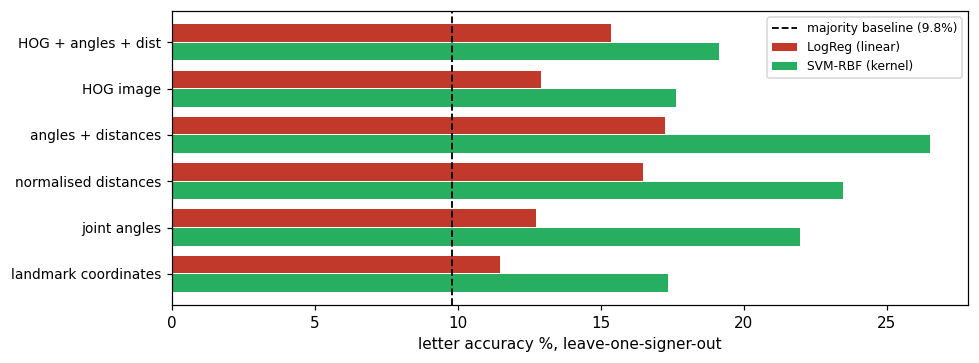

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.4))
idx = np.arange(len(table))
ax.barh(idx + 0.2, table["LogReg"], height=0.38, label="LogReg (linear)", color="#c0392b")
ax.barh(idx - 0.2, table["SVM-RBF"], height=0.38, label="SVM-RBF (kernel)", color="#27ae60")
ax.axvline(MAJORITY, color="k", ls="--", lw=1.2, label=f"majority baseline ({MAJORITY}%)")
ax.set_yticks(idx, table["features"], fontsize=9)
ax.set_xlabel("letter accuracy %, leave-one-signer-out")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Two things stand out.

**The estimator matters more than the representation.** SVM-RBF beats logistic regression on
*every* feature set, by 1.4–1.7×. With 1,345 samples over 40 classes the decision boundaries
are not linear, and a linear model cannot express them however good the features are.

**Landmark geometry is not dead.** `angles + distances` with an RBF kernel reaches ~26 %,
roughly double the HOG result that `letter_classifier.ipynb` called the best available. The
earlier failure was the three handicaps compounding, not a property of landmarks.

**Combining HOG with geometry makes things worse** (19.1 % against 26.5 %). HOG contributes
1,764 dimensions against geometry's 74, so after standardisation the geometric features are
drowned. If both are to be used, they need separate models and a combination at the decision
level.

## Honest evaluation: nested hyperparameter tuning

The table above used `C=10, gamma='scale'` chosen by hand. Tuning on the test signer would
inflate the result, so here the hyperparameters are selected **inside the training signers
only** — an inner leave-one-signer-out loop over the four training signers — and the held-out
signer is touched exactly once.

Word accuracy uses the same lexicon decoder as the live demo.

In [5]:
LEX = json.load(open("word_letter_mapping.json", encoding="utf-8"))
SEG = pd.read_csv("pseudo_label_segments.csv")
SPELL = {(r.signer_id, r.video_id): r.spelling for r in SEG.itertuples()}
F = hand_features(P)
GRID = [(C, g) for C in (1, 10, 100) for g in ("scale", 0.01, 0.1)]

def decode(Pr, classes, n, slack=1):
    ci = {c: i for i, c in enumerate(classes)}
    out = []
    for w, ls in LEX.items():
        if abs(len(ls) - n) > slack:
            continue
        L = min(len(ls), n); lp = 0.0; ok = True
        for i in range(L):
            j = ci.get(ls[i])
            if j is None: ok = False; break
            lp += np.log(max(Pr[i][j], 1e-12))
        if ok:
            out.append((lp / L - 0.7 * abs(len(ls) - n), w))
    out.sort(reverse=True)
    return [w for _, w in out]

rows = []
for s in sorted(set(signers)):
    tr, te = signers != s, signers == s
    best = None
    for C, g in GRID:                       # inner loop: training signers only
        acc = []
        for hold in sorted(set(signers[tr])):
            a, b = tr & (signers != hold), tr & (signers == hold)
            m = make_pipeline(StandardScaler(), SVC(C=C, gamma=g, class_weight="balanced"))
            m.fit(F[a], y[a]); acc.append((m.predict(F[b]) == y[b]).mean())
        mu = float(np.mean(acc))
        if best is None or mu > best[0]:
            best = (mu, C, g)
    _, C, g = best
    clf = make_pipeline(StandardScaler(),
                        SVC(C=C, gamma=g, class_weight="balanced", probability=True, random_state=0))
    clf.fit(F[tr], y[tr])
    classes = list(clf.named_steps["svc"].classes_)
    lacc = (clf.predict(F[te]) == y[te]).mean()

    Pr = clf.predict_proba(F[te]); vte = videos[te]
    t1 = t3 = nw = 0
    for v in sorted(set(vte)):
        w = SPELL.get((s, v))
        if w not in LEX:
            continue
        k = np.where(vte == v)[0]
        c = decode(Pr[k], classes, len(k)); nw += 1
        t1 += bool(c and c[0] == w); t3 += w in c[:3]
    rows.append({"held-out": s, "tuned on train only": f"C={C}, g={g}",
                 "letter %": 100*lacc, "word top-1 %": 100*t1/max(nw, 1),
                 "word top-3 %": 100*t3/max(nw, 1)})

nested = pd.DataFrame(rows)
print(nested.round(1).to_string(index=False))
print()
print(f"nested-tuned geometry + SVM : letters {nested['letter %'].mean():.1f}%  "
      f"word top-1 {nested['word top-1 %'].mean():.1f}%  top-3 {nested['word top-3 %'].mean():.1f}%")
print(f"previous best HOG + LogReg  : letters 13.2%  word top-1 33.1%  top-3 55.8%")

 held-out tuned on train only  letter %  word top-1 %  word top-3 %
signer1-F        C=10, g=0.01      22.5          59.2          83.7
signer2-F       C=10, g=scale      32.5          59.2          81.6
signer3-F        C=1, g=scale      25.1          64.4          91.1
signer4-L       C=10, g=scale      22.0          32.7          59.2
signer5-R       C=10, g=scale      27.2          50.0          65.4

nested-tuned geometry + SVM : letters 25.9%  word top-1 53.1%  top-3 76.2%
previous best HOG + LogReg  : letters 13.2%  word top-1 33.1%  top-3 55.8%


**Letters roughly double (13.2 % → 25.9 %) and words go from 33.1 % to 53.1 % top-1.**

The two tilted-angle signers remain the weakest, consistent with `angle_evaluation.ipynb`.

Worth noting the word figures against the right baseline: the decoder only considers words
whose length matches the detected hold count, leaving ~17 of 54 candidates, so chance is about
5.8 %, not 1.85 %. 53 % is roughly 9× chance.

## Other options worth trying, and why

What has been tested here is the cheapest end of the space. Ordered by expected value for this
dataset:

**Already demonstrated (above).** Kernel methods over invariance-engineered features. The gain
came from making the representation ignore hand morphology, and from an estimator that does
not need many samples per class to fit a boundary.

**Metric learning / prototypical networks.** Instead of training a 40-way classifier, learn an
embedding where the same letter lands near itself, then classify by nearest class prototype.
This is designed for a handful of examples per class, and it maps directly onto the
personal-calibration plan: a new user supplies a few examples per letter and the prototypes are
recomputed, with no retraining.

**Pretrained backbone as a frozen feature extractor.** A network pretrained on a large image
corpus, frozen, with only a linear head trained on our ~1,300 crops. Standard practice when
labels are scarce. Our CNN attempt failed partly because it was trained from scratch.

**Self-supervised pretraining on the unlabelled frames.** We have 72,087 frames but only 14,530
labelled hold frames. The transitions are unused. Contrastive pretraining on all of them, then
fine-tuning on the labelled subset, uses data we already have and currently discard.

**Signer-adversarial training.** Explicitly penalise the model for being able to identify the
signer, using the 97 % figure as the metric to drive down. Directly targets the measured
confound.

**Temporal modelling rather than per-letter classification.** Currently each hold is classified
independently and the lexicon is applied afterwards. A CTC or HMM decoder over the whole
sequence would use letter-transition structure during inference instead of after it.

**More data from the words we already exclude.** The 22 acronym words are ~30 % of the
vocabulary and contain several of the starved letters. This is not an algorithm, but with eight
classes at five examples each it may be worth more than any model change.